In [1]:
library(dplyr)
## visualization
library(ggplot2)
library(ggplot2)
library(gridExtra)
library(dplyr)
library(ggplot2)
library(cowplot)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union





Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
setwd("/home/liuxuan/metadata/10-10/PRJDB11398/")
initial_meta <- read.csv("SraRunTable.csv", header = TRUE)
head(initial_meta)
colnames(initial_meta)

,Run,Assay.Type,AvgSpotLen,Bases,BioProject,BioSample,Bytes,Center.Name,Consent,DATASTORE.filetype,⋯,LibrarySelection,LibrarySource,Organism,Platform,ReleaseDate,create_date,version,Sample.Name,Sample_name,SRA.Study
,<chr>,<chr>,<int>,<int>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>
1,DRR280689,RNA-Seq,260,30555000,PRJDB11398,SAMD00288108,15437534,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:20:00Z,1,SAMD00288108,sample10G_afterdec_Fp_clean.fq,DRP007622
2,DRR280690,RNA-Seq,246,8921381,PRJDB11398,SAMD00288109,5551730,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:20:00Z,1,SAMD00288109,sample10G_afterdec_Fup_clean.fq,DRP007622
3,DRR280691,RNA-Seq,165,19393221,PRJDB11398,SAMD00288110,12754105,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:50:00Z,1,SAMD00288110,sample10G_afterdec_Rp_clean.fq,DRP007622
4,DRR280692,RNA-Seq,125,27591,PRJDB11398,SAMD00288111,102038,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:19:00Z,1,SAMD00288111,sample10G_afterdec_Rup_clean.fq,DRP007622
5,DRR280693,RNA-Seq,262,53903029,PRJDB11398,SAMD00288112,26098059,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:16:00Z,1,SAMD00288112,sample10H_afterdec_Fp_clean.fq,DRP007622
6,DRR280694,RNA-Seq,245,9865167,PRJDB11398,SAMD00288113,6022509,TOKYO_MEDEN,public,"run.zq,sra",⋯,cDNA,METATRANSCRIPTOMIC,human oral metagenome,ILLUMINA,2021-08-24T00:00:00Z,2021-08-24T14:20:00Z,1,SAMD00288113,sample10H_afterdec_Fup_clean.fq,DRP007622


[1] "Run"                "Assay.Type"         "AvgSpotLen"        
 [4] "Bases"              "BioProject"         "BioSample"         
 [7] "Bytes"              "Center.Name"        "Consent"           
[10] "DATASTORE.filetype" "DATASTORE.provider" "DATASTORE.region"  
[13] "Experiment"         "Instrument"         "Library.Name"      
[16] "LibraryLayout"      "LibrarySelection"   "LibrarySource"     
[19] "Organism"           "Platform"           "ReleaseDate"       
[22] "create_date"        "version"            "Sample.Name"       
[25] "Sample_name"        "SRA.Study"

In [10]:
uniform_meta <- data.frame(
    BioProject = initial_meta$BioProject,
    Run = initial_meta$Run,
    sample_name = initial_meta$Sample_name,
    Age = NA,
    BMI = NA,
    Sex = NA,
    Region = NA,
    Platform = initial_meta$Platform,
    Country = NA,
    Site = NA,
    public_time = initial_meta$ReleaseDate,
    PCR_primers = NA,
    title = 'Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses',
    Disease_study = "YES",
    Status = NA,
    matched_samples = 'NO')

In [11]:
# 根据样本名称设置状态
for (i in 1:nrow(uniform_meta)) {
    sample_name <- uniform_meta$sample_name[i]
    
    if (grepl("H", sample_name, ignore.case = TRUE)) {
        uniform_meta$Site[i] <- "healthy"
    } else if (grepl("G", sample_name, ignore.case = TRUE)) {
        uniform_meta$Site[i] <- "gingivitis"
    } else if (grepl("P", sample_name, ignore.case = TRUE)) {
        uniform_meta$Site[i] <- "periodontitis"
    }
    # 如果不匹配任何模式，保持为NA
}
print(length(unique(uniform_meta$Run)))

print(length(unique(uniform_meta$sample_name)))

[1] 252
[1] 252


In [12]:
head(uniform_meta)

,BioProject,Run,sample_name,Age,BMI,Sex,Region,Platform,Country,Site,public_time,PCR_primers,title,Disease_study,Status,matched_samples
,<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>,<chr>,<lgl>,<chr>
1,PRJDB11398,DRR280689,sample10G_afterdec_Fp_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,gingivitis,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO
2,PRJDB11398,DRR280690,sample10G_afterdec_Fup_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,gingivitis,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO
3,PRJDB11398,DRR280691,sample10G_afterdec_Rp_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,gingivitis,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO
4,PRJDB11398,DRR280692,sample10G_afterdec_Rup_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,gingivitis,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO
5,PRJDB11398,DRR280693,sample10H_afterdec_Fp_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,healthy,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO
6,PRJDB11398,DRR280694,sample10H_afterdec_Fup_clean.fq,NA,NA,NA,NA,ILLUMINA,NA,healthy,2021-08-24T00:00:00Z,NA,"Discrimination of Bacterial Community Structures among Healthy, Gingivitis, and Periodontitis Statuses through Integrated Metatranscriptomic and Network Analyses",YES,NA,NO


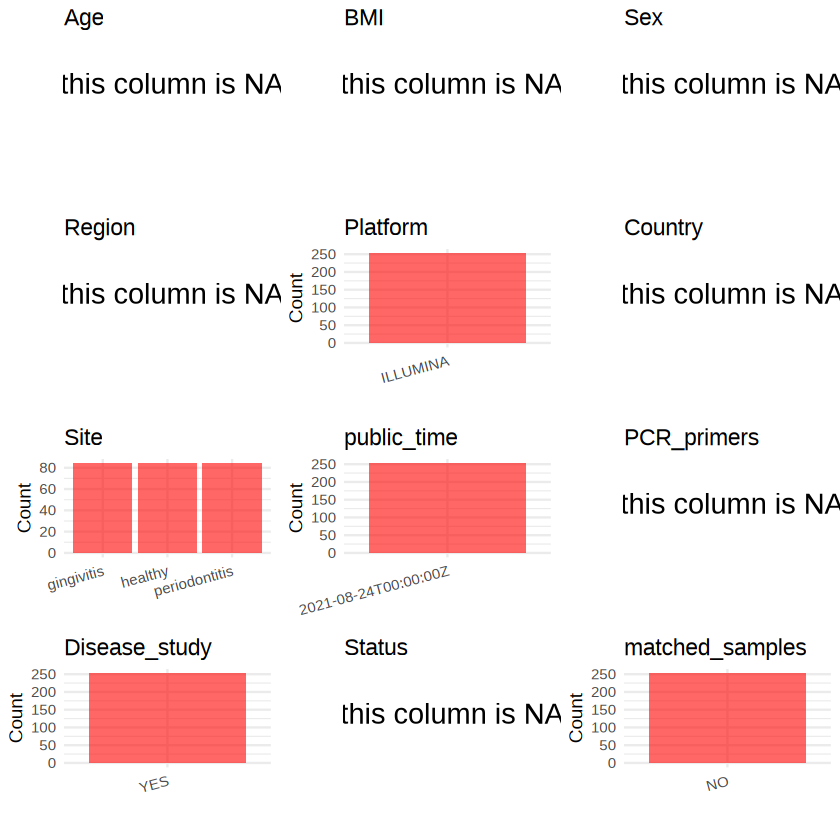

In [13]:
plot_data <- uniform_meta %>%
  select(-BioProject, -Run, -sample_name, -title)

create_simple_plots <- function(data) {
  plots <- list()
  
  for (col in colnames(data)) {
    if (all(is.na(data[[col]]))) {
      p <- ggplot() +
        annotate("text", x = 0.5, y = 0.5, label = "this column is NA", size = 6) +
        labs(title = col) +
        theme_void()
    } else if (is.numeric(data[[col]])) {
      p <- ggplot(data, aes(x = .data[[col]])) +
        geom_histogram(fill = "blue", alpha = 0.6, bins = 20, na.rm = TRUE) +
        labs(title = col) +
        theme_minimal()
    } else {
      count_data <- as.data.frame(table(data[[col]], useNA = "ifany"))
      p <- ggplot(count_data, aes(x = reorder(Var1, -Freq), y = Freq)) +
        geom_col(fill = "red", alpha = 0.6) +
        labs(title = col, x = NULL, y = "Count") +
        theme_minimal() +
        theme(axis.text.x = element_text(angle = 15, hjust = 1))
    }
    plots[[col]] <- p
  }
  return(plots)
}

plots <- create_simple_plots(plot_data)
p<-plot_grid(plots$Age, 
          plots$BMI, 
          plots$Sex, 
          plots$Region, 
          plots$Platform, 
          plots$Country, 
          plots$Site,
          plots$public_time, 
          plots$PCR_primers,
          plots$Disease_study,
          plots$Status,
          plots$matched_samples,# add 
          ncol = 3, align = "hv", axis = "lb")
p

In [14]:
uniform_meta <- uniform_meta[, c("BioProject", "Run", "sample_name", "Age", "BMI", "Sex", "Region", "Platform", "Country", "Site", "public_time", "PCR_primers", "title", "Disease_study", "Status")]
write.csv(uniform_meta, file = "/home/liuxuan/metadata/10-10/PRJDB11398/metadata.csv", quote = T)